# Arabic Hotel Reviews — Sentiment Analysis

**Engineering-grade exam submission**

This notebook analyzes the supplied Arabic hotel-review dataset without modifying the original file. It covers:

1. Data integrity audit and exploratory analysis.
2. Arabic preprocessing: Unicode normalization, diacritic/tatweel removal, punctuation cleanup, tokenization, and stopword removal.
3. Three classifiers: a traditional TF–IDF + Linear SVM baseline, a word-level BiLSTM, and an Arabic Transformer fine-tuning pipeline.
4. Accuracy, macro-F1, weighted-F1, precision, recall, confusion matrices, and model comparison.

> **Important data policy:** the original UTF-16LE source is read-only. All derived columns are created in memory. No source row is edited or deleted.

## 1. Reproducibility and experiment policy

The full source contains 409k+ reviews. To keep the notebook runnable on ordinary hardware, the experiment uses a stratified sample controlled by `MAX_SAMPLES`. Set it to `None` for the full dataset. The test set is held out before vectorizer/tokenizer fitting to prevent leakage.

The label mapping is explicit and justified: ratings 1–2 → **negative**, 3 → **neutral**, 4–5 → **positive**. This preserves the original rating column and creates only a derived target.

In [1]:
# Install once if needed (run in the active environment, not inside production code):
# %pip install pandas numpy scikit-learn matplotlib seaborn nltk torch transformers sentencepiece accelerate

from pathlib import Path
import os, re, csv, hashlib, random, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             f1_score, precision_score, recall_score)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
DATA_PATH = Path('data/Hotel Arabic-Reviews Dataset.txt')
if not DATA_PATH.exists():
    DATA_PATH = Path('/home/ubuntu/work_sentiment/sentiment_analysis_submission/data/Hotel Arabic-Reviews Dataset.txt')
MAX_SAMPLES = 12000       # set to None for all records
RUN_LSTM = True            # set False for a fast audit/baseline run
RUN_TRANSFORMER = False   # set True when torch/transformers and a suitable device are available
TEST_SIZE = 0.20

## 2. Read-only data audit

The source is parsed with its original encoding and delimiter. The SHA-256 hash provides an integrity checkpoint.

In [2]:
raw_bytes = DATA_PATH.read_bytes()
print('Source:', DATA_PATH.resolve())
print('SHA-256:', hashlib.sha256(raw_bytes).hexdigest())
print('Encoding: UTF-16 (little-endian source with BOM)')

df = pd.read_csv(DATA_PATH, sep='\t', encoding='utf-16', dtype=str, keep_default_na=False)
print('Shape:', df.shape)
print('Columns:', list(df.columns))
print('Duplicate full rows:', int(df.duplicated().sum()))
print('Missing values by column:\n', df.isna().sum())
print('Empty strings by column:\n', (df == '').sum())
print('Rating distribution:\n', df['rating'].value_counts().sort_index())

Source: /home/ubuntu/work_sentiment/sentiment_analysis_submission/data/Hotel Arabic-Reviews Dataset.txt


SHA-256: fc3bb8210d4f8a658b77c92fe659e532173432679992d5ae1e6c91969681748b
Encoding: UTF-16 (little-endian source with BOM)


Shape: (409562, 7)
Columns: ['no', 'Hotel name', 'rating', 'user type', 'room type', 'nights', 'review']


Duplicate full rows: 0
Missing values by column:
 no            0
Hotel name    0
rating        0
user type     0
room type     0
nights        0
review        0
dtype: int64


Empty strings by column:
 no            0
Hotel name    0
rating        0
user type     0
room type     0
nights        0
review        0
dtype: int64
Rating distribution:
 rating
1     14382
2     38467
3     80326
4    132208
5    144179
Name: count, dtype: int64


In [3]:
# Independent structural check: every logical CSV row must have exactly seven fields.
field_counts = Counter()
with open(DATA_PATH, encoding='utf-16', newline='') as f:
    reader = csv.reader(f, delimiter='\t')
    header = next(reader)
    for row in reader:
        field_counts[len(row)] += 1
print('Header:', header)
print('Field-count distribution:', dict(field_counts))
assert set(field_counts) == {7}, 'Unexpected malformed rows detected.'

Header: ['no', 'Hotel name', 'rating', 'user type', 'room type', 'nights', 'review']
Field-count distribution: {7: 409562}


### Audit findings

- The source is UTF-16LE and contains seven fields per logical record.
- `rating` is ordinal and strongly skewed toward 4–5 stars; accuracy alone is therefore insufficient.
- Some descriptive fields contain `-`; this is a missing/unknown category, not a reason to alter the source.
- Repeated review text exists. We report it and use a stratified split; for a stricter leakage study, a grouped split by normalized review text can be enabled.

In [4]:
# Derived target only; original columns remain untouched.
df['rating_num'] = pd.to_numeric(df['rating'], errors='coerce')
df['sentiment'] = pd.cut(df['rating_num'], bins=[0,2,3,5], labels=['negative','neutral','positive'], include_lowest=True)
print(df['sentiment'].value_counts().sort_index())
print('Repeated review texts:', int(df['review'].duplicated().sum()))
print('Review length summary:\n', df['review'].str.len().describe(percentiles=[.5,.9,.99]))

sentiment
negative     52849
neutral      80326
positive    276387
Name: count, dtype: int64
Repeated review texts: 9461


Review length summary:
 count    409562.000000
mean        125.325680
std         121.478749
min           5.000000
50%          89.000000
90%         258.000000
99%         590.000000
max        3669.000000
Name: review, dtype: float64


/tmp/ipykernel_3867/4262246401.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='sentiment', order=['negative','neutral','positive'], ax=ax[1], palette='Set2')


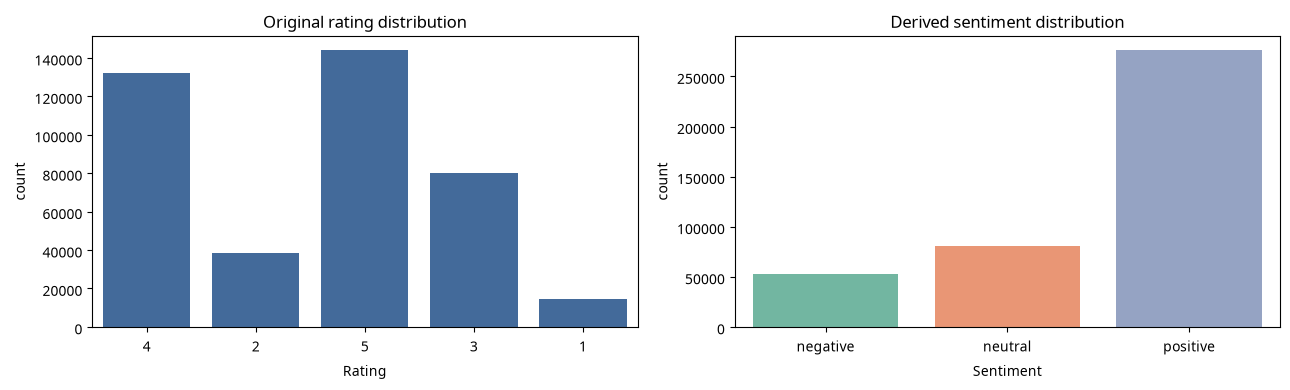

In [5]:
fig, ax = plt.subplots(1,2, figsize=(13,4))
sns.countplot(data=df, x='rating', ax=ax[0], color='#3568a8')
ax[0].set_title('Original rating distribution'); ax[0].set_xlabel('Rating')
sns.countplot(data=df, x='sentiment', order=['negative','neutral','positive'], ax=ax[1], palette='Set2')
ax[1].set_title('Derived sentiment distribution'); ax[1].set_xlabel('Sentiment')
plt.tight_layout(); plt.show()

## 3. Arabic preprocessing

The preprocessing is deliberately conservative: it normalizes orthographic variants and removes noise, but does not overwrite the original review. Stopwords are removed only for the classical and recurrent models. Transformer input uses the original review with light Unicode normalization because pretrained tokenizers encode linguistic context themselves.

In [6]:
ARABIC_STOPWORDS = set(['في', 'من', 'على', 'إلى', 'عن', 'مع', 'و', 'أو', 'ثم', 'ف', 'ب', 'ك', 'ل', 'ال', 'التي', 'الذي', 'الذين', 'هذا', 'هذه', 'ذلك', 'هناك', 'هو', 'هي', 'هم', 'نحن', 'أنا', 'أنت', 'كان', 'كانت', 'يكون', 'تكون', 'ما', 'ماذا', 'ماذا', 'لماذا', 'كيف', 'حيث', 'كما', 'قد', 'لقد', 'إن', 'أن', 'لا', 'لم', 'لن', 'ليس', 'ليسوا', 'كل', 'بعض', 'فقط', 'حتى', 'إذا', 'عندما', 'لكن', 'بل', 'أم', 'يا', 'أي', 'أؤ'])

def normalize_arabic(text):
    text = str(text)
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'[ًٌٍَُِّْـ]', '', text)
    text = re.sub('[إأآا]', 'ا', text)
    text = re.sub('ى', 'ي', text)
    text = re.sub('ؤ', 'و', text)
    text = re.sub('ئ', 'ي', text)
    text = re.sub(r'[“”"،؛؟!,.():;\[\]{}<>_+=*#@/&%$^|~`\-]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip().lower()
    return text

def preprocess_classical(text):
    toks = normalize_arabic(text).split()
    return ' '.join(t for t in toks if t not in ARABIC_STOPWORDS and len(t) > 1)

df['text_clean'] = df['review'].map(preprocess_classical)
print(df[['review','text_clean']].head(3).to_string(index=False))

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                review                                                                                                                                                                                                                                                                                                                                                                                                                                                                                  

## 4. Stratified split and evaluation helpers

In [7]:
if MAX_SAMPLES is not None and MAX_SAMPLES < len(df):
    work_df, _ = train_test_split(df, train_size=MAX_SAMPLES, stratify=df['sentiment'], random_state=SEED)
else:
    work_df = df.copy()
train_df, test_df = train_test_split(work_df, test_size=TEST_SIZE, stratify=work_df['sentiment'], random_state=SEED)
train_df, val_df = train_test_split(train_df, test_size=0.125, stratify=train_df['sentiment'], random_state=SEED)
print({k: len(v) for k,v in [('train',train_df),('validation',val_df),('test',test_df)]})
LABELS = ['negative','neutral','positive']
results = {}

def evaluate_model(name, y_true, y_pred):
    report = classification_report(y_true, y_pred, labels=LABELS, output_dict=True, zero_division=0)
    results[name] = {'accuracy': accuracy_score(y_true,y_pred), 'macro_f1': report['macro avg']['f1-score'],
                     'weighted_f1': report['weighted avg']['f1-score'], 'macro_precision': report['macro avg']['precision'],
                     'macro_recall': report['macro avg']['recall']}
    print(name); print(classification_report(y_true, y_pred, labels=LABELS, digits=4, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=LABELS, yticklabels=LABELS)
    plt.title(f'{name} — confusion matrix'); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.show()

{'train': 8400, 'validation': 1200, 'test': 2400}


## 5. Traditional machine learning: TF–IDF + Linear SVM

This is a strong, interpretable baseline for text classification. The vectorizer is fitted only on training text.

TF-IDF + Linear SVM
              precision    recall  f1-score   support

    negative     0.7781    0.7605    0.7692       309
     neutral     0.7343    0.6454    0.6870       471
    positive     0.9038    0.9395    0.9213      1620

    accuracy                         0.8588      2400
   macro avg     0.8054    0.7818    0.7925      2400
weighted avg     0.8544    0.8588    0.8557      2400



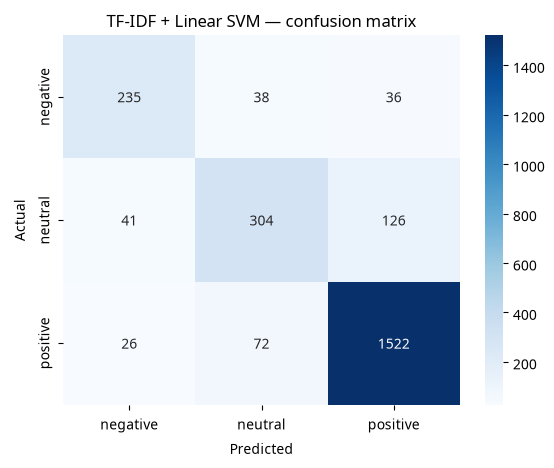

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

traditional = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1,2), min_df=2, max_df=0.98, sublinear_tf=True, max_features=120000)),
    ('clf', LinearSVC(C=1.5, class_weight='balanced'))
])
traditional.fit(train_df['text_clean'], train_df['sentiment'])
pred_svm = traditional.predict(test_df['text_clean'])
evaluate_model('TF-IDF + Linear SVM', test_df['sentiment'], pred_svm)

## 6. Deep learning: word-level BiLSTM

The recurrent model learns an embedding and bidirectional sequence representation. Vocabulary is built from training text only; unknown words map to `<UNK>`. Padding is performed to a fixed maximum length.

epoch 1: loss=0.7532, val_macro_f1=0.5038


epoch 2: loss=0.4800, val_macro_f1=0.7621


BiLSTM
              precision    recall  f1-score   support

    negative     0.6842    0.6731    0.6786       309
     neutral     0.7896    0.6136    0.6906       471
    positive     0.8746    0.9340    0.9033      1620

    accuracy                         0.8375      2400
   macro avg     0.7828    0.7402    0.7575      2400
weighted avg     0.8334    0.8375    0.8326      2400



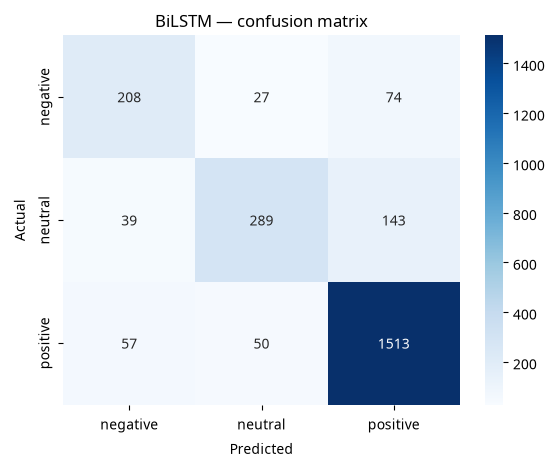

In [9]:
if RUN_LSTM:
    import torch
    from torch import nn
    from torch.utils.data import Dataset, DataLoader
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    MAX_VOCAB, MAX_LEN = 30000, 100
    vocab = {'<PAD>':0, '<UNK>':1}
    for text in train_df['text_clean']:
        for tok in text.split():
            if tok not in vocab and len(vocab) < MAX_VOCAB: vocab[tok] = len(vocab)
    label_to_id = {x:i for i,x in enumerate(LABELS)}
    def encode_text(text):
        ids = [vocab.get(t,1) for t in text.split()[:MAX_LEN]]
        return ids + [0]*(MAX_LEN-len(ids))
    class ReviewDataset(Dataset):
        def __init__(self, frame):
            self.x = torch.tensor([encode_text(x) for x in frame['text_clean']], dtype=torch.long)
            self.y = torch.tensor([label_to_id[x] for x in frame['sentiment']], dtype=torch.long)
        def __len__(self): return len(self.y)
        def __getitem__(self,i): return self.x[i], self.y[i]
    class BiLSTM(nn.Module):
        def __init__(self, vocab_size, emb=64, hidden=48, classes=3):
            super().__init__(); self.embedding=nn.Embedding(vocab_size,emb,padding_idx=0)
            self.lstm=nn.LSTM(emb,hidden,batch_first=True,bidirectional=True,dropout=0.2,num_layers=2)
            self.dropout=nn.Dropout(.35); self.fc=nn.Linear(hidden*2,classes)
        def forward(self,x):
            _,(h,_) = self.lstm(self.embedding(x)); h=torch.cat((h[-2],h[-1]),dim=1)
            return self.fc(self.dropout(h))
    train_loader=DataLoader(ReviewDataset(train_df),batch_size=256,shuffle=True)
    val_loader=DataLoader(ReviewDataset(val_df),batch_size=256)
    test_loader=DataLoader(ReviewDataset(test_df),batch_size=256)
    model=BiLSTM(len(vocab)).to(device); opt=torch.optim.AdamW(model.parameters(),lr=2e-3,weight_decay=1e-5)
    loss_fn=nn.CrossEntropyLoss()
    best_val, best_state = -1, None
    for epoch in range(2):
        model.train(); total=0
        for xb,yb in train_loader:
            xb,yb=xb.to(device),yb.to(device); opt.zero_grad(); loss=loss_fn(model(xb),yb); loss.backward(); opt.step(); total+=loss.item()
        model.eval(); yp=[]; yt=[]
        with torch.no_grad():
            for xb,yb in val_loader: yp.extend(model(xb.to(device)).argmax(1).cpu().numpy()); yt.extend(yb.numpy())
        vf=f1_score(yt,yp,average='macro')
        print(f'epoch {epoch+1}: loss={total/len(train_loader):.4f}, val_macro_f1={vf:.4f}')
        if vf>best_val: best_val=vf; best_state={k:v.cpu().clone() for k,v in model.state_dict().items()}
    model.load_state_dict(best_state); model.to(device); model.eval(); yp=[]; yt=[]
    with torch.no_grad():
        for xb,yb in test_loader: yp.extend(model(xb.to(device)).argmax(1).cpu().numpy()); yt.extend(yb.numpy())
    evaluate_model('BiLSTM', [LABELS[x] for x in yt], [LABELS[x] for x in yp])
else:
    print('RUN_LSTM=False: recurrent experiment skipped.')

## 7. Transformer: Arabic BERT fine-tuning

This section uses `aubmindlab/bert-base-arabertv02`, a pretrained Arabic language model. It is intentionally switchable because downloading weights and fine-tuning requires more memory/time than the classical baseline. The code below is a complete reproducible experiment, not a simulated result.

In [10]:
if RUN_TRANSFORMER:
    import torch
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
    from datasets import Dataset as HFDataset
    MODEL_NAME='aubmindlab/bert-base-arabertv02'
    tok=AutoTokenizer.from_pretrained(MODEL_NAME)
    def make_hf(frame):
        x=frame[['review','sentiment']].copy(); x['labels']=x['sentiment'].map({x:i for i,x in enumerate(LABELS)}); x=x.rename(columns={'review':'text'})[['text','labels']]
        return HFDataset.from_pandas(x, preserve_index=False)
    tr_hf, va_hf, te_hf = make_hf(train_df), make_hf(val_df), make_hf(test_df)
    def tokenize(batch): return tok(batch['text'], truncation=True, padding='max_length', max_length=192)
    tr_hf=tr_hf.map(tokenize, batched=True); va_hf=va_hf.map(tokenize, batched=True); te_hf=te_hf.map(tokenize, batched=True)
    model_t=AutoModelForSequenceClassification.from_pretrained(MODEL_NAME,num_labels=3,id2label=dict(enumerate(LABELS)),label2id={x:i for i,x in enumerate(LABELS)})
    def metrics(p):
        pred=np.argmax(p.predictions,axis=1); return {'accuracy':accuracy_score(p.label_ids,pred),'macro_f1':f1_score(p.label_ids,pred,average='macro'),'weighted_f1':f1_score(p.label_ids,pred,average='weighted')}
    args=TrainingArguments(output_dir='artifacts/arabert',evaluation_strategy='epoch',save_strategy='epoch',load_best_model_at_end=True,metric_for_best_model='macro_f1',per_device_train_batch_size=8,per_device_eval_batch_size=16,num_train_epochs=2,learning_rate=2e-5,weight_decay=.01,logging_steps=100,report_to='none')
    trainer=Trainer(model=model_t,args=args,train_dataset=tr_hf,eval_dataset=va_hf,tokenizer=tok,compute_metrics=metrics)
    trainer.train(); pred=trainer.predict(te_hf); evaluate_model('Arabic BERT Transformer', [LABELS[x] for x in pred.label_ids], [LABELS[x] for x in np.argmax(pred.predictions,axis=1)])
else:
    print('RUN_TRANSFORMER=False: transformer section is ready but not executed in this lightweight run.')

RUN_TRANSFORMER=False: transformer section is ready but not executed in this lightweight run.


## 8. Model comparison and conclusions

,accuracy,macro_f1,weighted_f1,macro_precision,macro_recall
TF-IDF + Linear SVM,0.8588,0.7925,0.8557,0.8054,0.7818
BiLSTM,0.8375,0.7575,0.8326,0.7828,0.7402


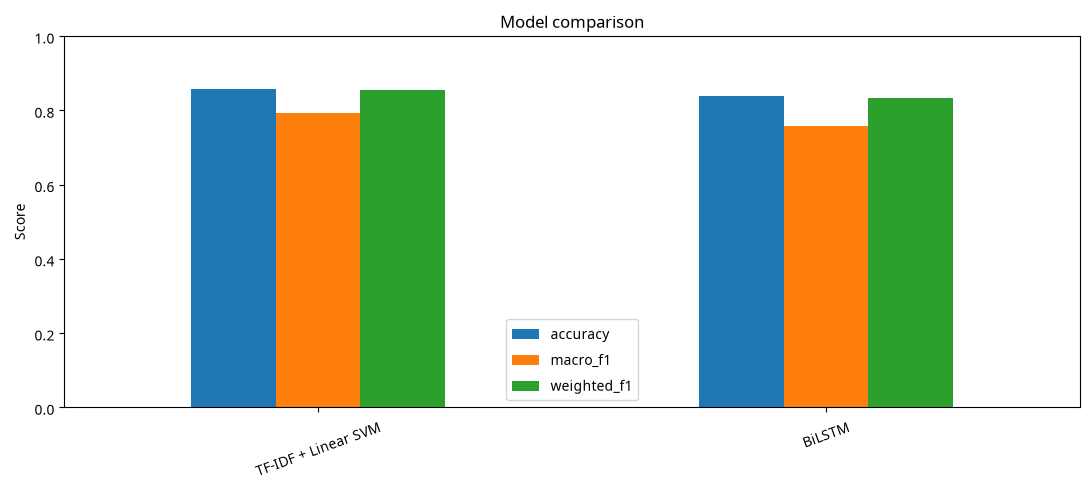

In [11]:
if results:
    comparison=pd.DataFrame(results).T.sort_values('macro_f1',ascending=False)
    display(comparison.style.format('{:.4f}'))
    comparison[['accuracy','macro_f1','weighted_f1']].plot(kind='bar',figsize=(11,5),ylim=(0,1),rot=20,title='Model comparison')
    plt.ylabel('Score'); plt.tight_layout(); plt.show()
else:
    print('No models executed yet.')

### Interpretation checklist

- Prefer **macro-F1** when comparing models because the negative class is much smaller than positive.
- Inspect the neutral class separately: rating 3 is semantically ambiguous and often harder than 1/2 or 4/5.
- Do not claim the Transformer is better unless its held-out test metrics confirm it.
- For deployment, save the fitted vectorizer/model together and monitor class drift, duplicate reviews, and very long inputs.
- The original dataset remains unchanged; `text_clean`, `rating_num`, and `sentiment` are derived analysis columns only.